# E3: METHODE DE CLASSIFICATION

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

def creer_modele_classification_robuste(input_dim=1024, num_classes=10):
    """
    Construit un réseau de neurones optimisé pour le déploiement en direct.
    Utilise 'sigmoid' pour permettre le rejet des bruits inconnus (silence/bruit de fond).
    """
    model = Sequential([
        # 1. Normalisation des embeddings en entrée pour lisser les différences de micros
        BatchNormalization(input_shape=(input_dim,)),

        # Première couche dense
        Dense(512, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),

        # Deuxième couche cachée
        Dense(256, activation='relu'),
        Dropout(0.4),

        # 2. Couche de sortie avec 'sigmoid' au lieu de 'softmax'
        # Permet à chaque classe d'être évaluée indépendamment entre 0 et 1.
        Dense(num_classes, activation='sigmoid')
    ])

    # Compilation du modèle
    # ATTENTION : Si vous passez à 'sigmoid', la fonction de perte doit être
    # 'binary_crossentropy', même pour du multi-classe.
    # Vos labels cibles (Y) doivent être encodés en One-Hot (ex: avec to_categorical).
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Adapter NUM_CLASSES à votre sous-ensemble de l'ESC-50 (ex: 10 ou 50)
NUM_CLASSES = 10
model_classification = creer_modele_classification_robuste(input_dim=1024, num_classes=NUM_CLASSES)
model_classification.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/normalization/batch_normalization.py:142: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 662,794 (2.53 MB)

 Trainable params: 660,746 (2.52 MB)

 Non-trainable params: 2,048 (8.00 KB)

Extraction des classes visées et gestions de bruits d'environnement

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import json

# 1. Définition des chemins avec le sous-dossier ESC-50-master
dossier_esc50 = '/content/drive/MyDrive/ESC-50'
dossier_audio = os.path.join(dossier_esc50, 'ESC-50-master', 'audio')
csv_metadonnees = os.path.join(dossier_esc50, 'ESC-50-master', 'meta', 'esc50.csv')

# 2. Chargement du fichier CSV officiel
df_meta = pd.read_csv(csv_metadonnees)

# 3. FILTRAGE STRICT POUR NE GARDER QUE LES BRUITS DOMESTIQUES ET QUOTIDIENS
classes_domestiques_cibles = [
    'crying_baby',           # Bébé qui pleure
    'siren',              # Sirène
    'clapping',           # Applaudissements
    'door_wood_knock',    # Toc-toc à la porte
    'glass_breaking',     # Verre brisé
    'car_horn',           # Klaxon de voiture
    'pouring_water',      # Gouttes d'eau / fuite
    'washing_machine',    # Machine à laver
    'crackling_fire',      # Crépitement de feu
    'clock_alarm'         # Alarme de réveil
]

# Filtrage du DataFrame
df_filtre = df_meta[df_meta['category'].isin(classes_domestiques_cibles)].copy()

# Création d'un dictionnaire de mapping fixe (ex: 'baby_cry' -> 0, 'clock_alarm' -> 1, etc.)
classes_uniques = sorted(df_filtre['category'].unique())  # Trié pour garder un ordre strict au redémarrage
mapping_classes = {classe: idx for idx, classe in enumerate(classes_uniques)}
df_filtre['target_label'] = df_filtre['category'].map(mapping_classes)

print(f"Nombre total de fichiers de bruits domestiques sélectionnés : {len(df_filtre)}")
print(f"Classes incluses ({len(classes_uniques)} classes) :")
for nom, idx in mapping_classes.items():
    print(f" - ID {idx} : {nom}")

# Sauvegarder impérativement le mapping dans Google Drive !
chemin_mapping_drive = "/content/drive/MyDrive/mapping_classes.json"
with open(chemin_mapping_drive, "w") as f:
    json.dump(mapping_classes, f)

print("Mapping sauvegardé avec succès dans le Drive :", chemin_mapping_drive)

# 4. BOUCLE D'EXTRACTION DES EMBEDDINGS YAMNET AVEC SÉCURITÉ
X_embeddings = []
y_labels = []

print("\nDébut de l'extraction des embeddings YAMNet...")
for index, row in df_filtre.iterrows():
    nom_fichier = row['filename']
    label_id = row['target_label']

    chemin_complet = os.path.join(dossier_audio, nom_fichier)

    if os.path.exists(chemin_complet):
        try:
            # Utilisation sécurisée de la fonction d'extraction
            emb, _ = extraire_embeddings(chemin_complet, is_bytes=False)
            X_embeddings.append(emb)
            y_labels.append(label_id)
        except Exception as e:
            # Si un fichier WAV spécifique est corrompu ou illisible, on passe au suivant
            print(f"⚠️ Fichier ignoré car corrompu ou illisible : {nom_fichier} | Erreur : {e}")
    else:
        print(f"Alerte : Fichier introuvable -> {chemin_complet}")

# Conversion en tableaux NumPy
X_data = np.array(X_embeddings)
y_data = np.array(y_labels)

# --- MODIFICATION CRUCIALE POUR LA COUCHE SIGMOID EN SORTIE ---
# Encodage en One-Hot pour correspondre à la fonction de perte 'binary_crossentropy'
y_data_onehot = to_categorical(y_data, num_classes=len(classes_uniques))

print(f"\nForme finale de la matrice X_data (Embeddings) : {X_data.shape}")
print(f"Forme finale de la matrice y_data_onehot (One-Hot) : {y_data_onehot.shape}")

Nombre total de fichiers de bruits domestiques sélectionnés : 400
Classes incluses (10 classes) :
 - ID 0 : car_horn
 - ID 1 : clapping
 - ID 2 : clock_alarm
 - ID 3 : crackling_fire
 - ID 4 : crying_baby
 - ID 5 : door_wood_knock
 - ID 6 : glass_breaking
 - ID 7 : pouring_water
 - ID 8 : siren
 - ID 9 : washing_machine
Mapping sauvegardé avec succès dans le Drive : /content/drive/MyDrive/mapping_classes.json

Début de l'extraction des embeddings YAMNet...


/tmp/ipykernel_2631/2260703495.py:24: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(source_audio, sr=None, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


⚠️ Fichier ignoré car corrompu ou illisible : 2-89516-A-37.wav | Erreur : 

Forme finale de la matrice X_data (Embeddings) : (399, 1024)
Forme finale de la matrice y_data_onehot (One-Hot) : (399, 10)


# E4: ENTRAINEMENT

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

print("--- DEBUT DU PIPELINE D'ENTRAÎNEMENT ROBUSTE ---")

# 1. UNIQUE DIVISION DES DONNÉES (Faites-le sur les données brutes extraites)
# X_data et y_data proviennent STRICTEMENT de votre boucle d'extraction ESC-50
X_train_brut, X_val, y_train_brut, y_val_brut = train_test_split(
    X_data, y_data,
    test_size=0.2,
    random_state=42,
    stratify=y_data
)

# 2. AUGMENTATION DE ROBUSTESSE (Uniquement appliquée sur le bloc d'entraînement isolé)
print("Dopage de la robustesse (Microphone virtuel) sur le jeu d'entraînement...")
X_train_robuste = []
y_train_robuste = []

for embedding, label in zip(X_train_brut, y_train_brut):
    # On conserve la version originale propre
    X_train_robuste.append(embedding)
    y_train_robuste.append(label)

    # On crée une réplique avec du bruit pour simuler les parasites du micro Streamlit
    bruit_embedding = np.random.normal(0, 0.06, embedding.shape)
    X_train_robuste.append(embedding + bruit_embedding)
    y_train_robuste.append(label)

# Conversion des listes augmentées en tableaux NumPy
X_train = np.array(X_train_robuste)
y_train_entiers = np.array(y_train_robuste)

# 3. ENCODAGE ONE-HOT SIMULTANÉ (Pour la perte binary_crossentropy)
# Calcul dynamique du nombre de classes (qui doit être égal à 8)
NUM_CLASSES = len(np.unique(y_data))

y_train = to_categorical(y_train_entiers, num_classes=NUM_CLASSES)
y_val = to_categorical(y_val_brut, num_classes=NUM_CLASSES)

print(f"\nVérification finale des dimensions avant d'alimenter Keras :")
print(f" -> Données Entraînement : X = {X_train.shape}, Y = {y_train.shape}")
print(f" -> Données Validation   : X = {X_val.shape}, Y = {y_val.shape}")

# 4. CONFIGURATION DE LA SAUVEGARDE ET DE L'ARRÊT PRÉCOCE
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Format standardisé .keras pour figer la BatchNormalization
chemin_sauvegarde = '/content/drive/MyDrive/modele_bruits_domestiques_robuste.keras'

checkpoint = ModelCheckpoint(
    chemin_sauvegarde,
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# 5. LANCEMENT DU FIT
print("\nEntraînement en cours...")
history = model_classification.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

print(f"\n✅ Pipeline terminé ! Modèle sécurisé sauvegardé dans : {chemin_sauvegarde}")


--- DEBUT DU PIPELINE D'ENTRAÎNEMENT ROBUSTE ---
Dopage de la robustesse (Microphone virtuel) sur le jeu d'entraînement...

Vérification finale des dimensions avant d'alimenter Keras :
 -> Données Entraînement : X = (638, 1024), Y = (638, 10)
 -> Données Validation   : X = (80, 1024), Y = (80, 10)

Entraînement en cours...
Epoch 1/50
36/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2753 - loss: 1.1722
Epoch 1: val_accuracy improved from None to 0.81250, saving model to /content/drive/MyDrive/modele_bruits_domestiques_robuste.keras

Epoch 1: finished saving model to /content/drive/MyDrive/modele_bruits_domestiques_robuste.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.4577 - loss: 1.0346 - val_accuracy: 0.8125 - val_loss: 0.8790
Epoch 2/50
37/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7192 - loss: 0.8317
Epoch 2: val_accuracy improved from 0.81250 to 0.91250, saving model to /content/drive/MyDrive/modele_bruits_domestiques_robuste.keras

Epoch 2: finished saving 

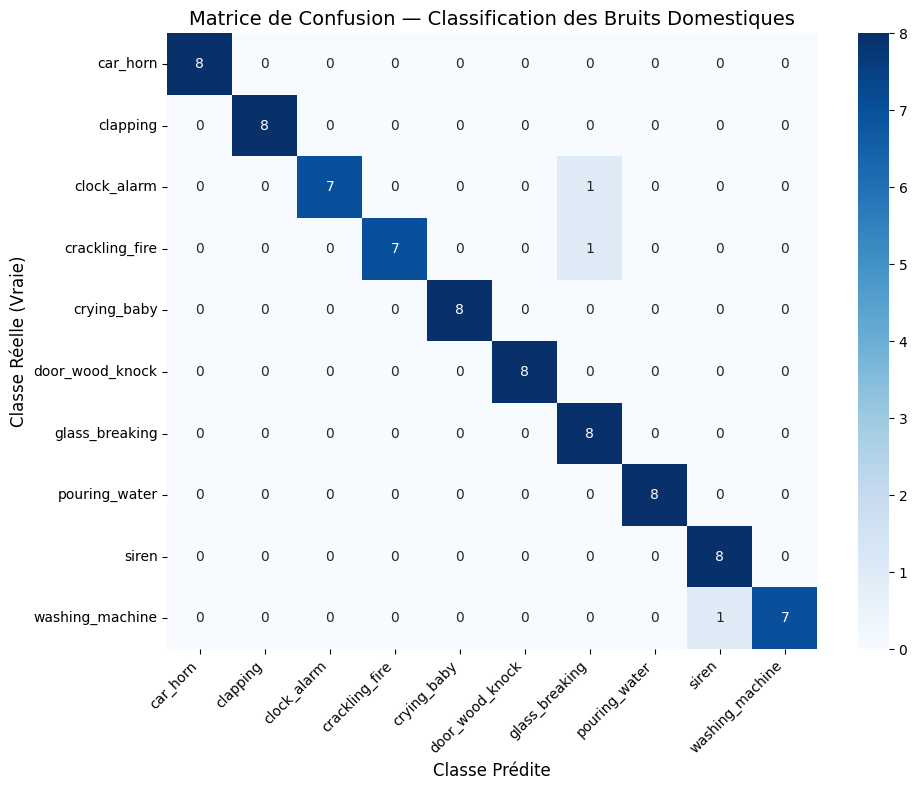

=== RAPPORT DE CLASSIFICATION ===

                 precision    recall  f1-score   support

          car_horn       1.00      1.00      1.00         8
          clapping       1.00      1.00      1.00         8
       clock_alarm       1.00      0.88      0.93         8
    crackling_fire       1.00      0.88      0.93         8
       crying_baby       1.00      1.00      1.00         8
    door_wood_knock      1.00      1.00      1.00         8
    glass_breaking       0.80      1.00      0.89         8
    pouring_water        1.00      1.00      1.00         8
    siren        0.89    1.00      0.94         8
    washing_machine      1.00      0.88      0.93         8



    accuracy                                 0.96        80
    macro avg            0.97      0.96      0.96        80
    weighted avg         0.97      0.96      0.96        80


In [ ]:
import json
import os
import tensorflow as tf

# 1. Récupération sécurisée du modèle
try:
    if 'model_classification' not in globals():
        print("Chargement du modèle sauvegardé depuis Google Drive...")
        model_classification = tf.keras.models.load_model('/content/drive/MyDrive/modele_bruits_domestiques_robuste.keras')
    else:
        model_classification = globals()['model_classification']
except Exception as e:
    print(f"Impossible de charger le modèle : {e}")

# 2. Récupération sécurisée et test du mapping des classes
chemin_mapping_drive = "/content/drive/MyDrive/mapping_classes.json"
mapping_classes = None

if os.path.exists(chemin_mapping_drive):
    with open(chemin_mapping_drive, "r") as f:
        mapping_classes = json.load(f)

# Si le fichier est vide ou absent, on le régénère à partir de vos classes cibles standards
if not mapping_classes:
    print("⚠️ Fichier JSON vide ou introuvable. Recréation automatique du mapping...")
    classes_domestiques_cibles = [
        'crying_baby', 'siren', 'clapping', 'door_wood_knock',
        'glass_breaking', 'car_horn', 'pouring_water',
        'washing_machine', 'crackling_fire', 'clock_alarm'
    ]
    classes_uniques = sorted(classes_domestiques_cibles)
    mapping_classes = {classe: idx for idx, classe in enumerate(classes_uniques)}

    # Sauvegarde propre
    with open(chemin_mapping_drive, "w") as f:
        json.dump(mapping_classes, f)
    print("✅ Mapping recréé et sauvegardé avec succès !")
else:
    print("Mapping chargé avec succès depuis le Drive.")

Mapping chargé avec succès depuis le Drive.


In [ ]:
!pip install streamlit streamlit_mic_recorder pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 82.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 64.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 37.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [streamlit_mic_recorder]


In [ ]:
%%writefile app.py
import io
import os
import time
import uuid
from datetime import datetime

import numpy as np
import requests
import streamlit as st
import streamlit.components.v1 as components
import tensorflow as tf
import tensorflow_hub as hub
from pydub import AudioSegment
from streamlit_mic_recorder import mic_recorder
import json

# =============================================================================
# CONFIGURATION
# =============================================================================
YAMNET_URL = "https://tfhub.dev/google/yamnet/1"
MODEL_PATH = "/content/drive/MyDrive/modele_bruits_domestiques_robuste.keras"
MAPPING_PATH = "/content/drive/MyDrive/mapping_classes.json"

DUREE_CLIGNOTEMENT = 15   # secondes (1 flash par seconde, fondu doux)
SEUIL_SILENCE = 0.005     # amplitude RMS en dessous de laquelle on considère le silence
MAX_HISTORIQUE = 30

st.set_page_config(
    page_title="Assistant Visuel Sonore",
    page_icon="🤟",
    layout="centered",
    initial_sidebar_state="collapsed",
)

# =============================================================================
# TRADUCTIONS, ÉMOJIS ET COULEURS PAR CLASSE
# =============================================================================
TRADUCTION_CLASSES = {
    "Baby Cry":        {"nom": "Bébé qui pleure",               "emoji": "👶🚨", "couleur": "#EF6C00", "fond": "#FFE0B2"},
    "Siren":           {"nom": "Sirène d'alerte / Ambulance",   "emoji": "📢🚨", "couleur": "#C62828", "fond": "#FFCDD2"},
    "Clapping":        {"nom": "Applaudissements",              "emoji": "👏🎉", "couleur": "#2E7D32", "fond": "#C8E6C9"},
    "Door Wood Knock": {"nom": "Quelqu'un frappe à la porte",   "emoji": "🚪✊", "couleur": "#1565C0", "fond": "#BBDEFB"},
    "Glass Breaking":  {"nom": "Verre ou vaisselle cassée",     "emoji": "💥🥛", "couleur": "#B71C1C", "fond": "#FFCDD2"},
    "Car Horn":        {"nom": "Klaxon de voiture",             "emoji": "🚗🔊", "couleur": "#1565C0", "fond": "#BBDEFB"},
    "Pouring Water":   {"nom": "Eau qui coule / Fuite d'eau",   "emoji": "💧🚰", "couleur": "#EF6C00", "fond": "#FFE0B2"},
    "Clock Alarm":     {"nom": "Alarme de réveil / Minuteur",   "emoji": "⏰🔔", "couleur": "#F9A825", "fond": "#FFF3CD"},
    "Crackling Fire":  {"nom": "Feu qui crépite",               "emoji": "🔥🚨", "couleur": "#BF360C", "fond": "#FFCCBC"},
}
INFOS_PAR_DEFAUT = {"nom": "Bruit inconnu", "emoji": "🔔", "couleur": "#546E7A", "fond": "#ECEFF1"}


def infos_classe(nom_brut: str) -> dict:
    """Normalise le nom de classe du modèle et renvoie sa traduction FR."""
    cle = nom_brut.replace("_", " ").title()
    return TRADUCTION_CLASSES.get(cle, {**INFOS_PAR_DEFAUT, "nom": cle})


# =============================================================================
# STYLE MOBILE (CSS)
# =============================================================================
st.markdown(
    """
<style>
#MainMenu, footer {visibility: hidden;}
.block-container {padding: 1rem 1rem 6rem 1rem; max-width: 520px;}

.titre-app {text-align:center; font-size:1.5rem; font-weight:800; margin:0;}
.sous-titre {text-align:center; opacity:.7; font-size:.95rem; margin:.2rem 0 0 0;}

/* Zone centrale : le bouton micro est au milieu de l'écran */
.espace-haut {height: 14vh;}
.espace-bas  {height: 8vh;}
.consigne {text-align:center; opacity:.75; font-size:1rem; margin-top:.6rem;}

/* Carte d'alerte (en bas) */
.carte-alerte {
    padding: 28px 16px; border-radius: 24px; text-align: center;
    border-left: 14px solid; box-shadow: 0 4px 14px rgba(0,0,0,.18);
}
.carte-alerte .emoji {font-size: 84px; line-height: 1.1; margin-bottom: 8px;}
.carte-alerte .nom   {font-size: 1.9rem; font-weight: 800; margin: 0; letter-spacing: .5px;}
.carte-alerte .info  {font-size: 1rem; margin-top: 10px; opacity: .85;}
.carte-neutre {
    padding: 22px 16px; border-radius: 20px; text-align:center;
    background:#ECEFF1; color:#37474F; font-size:1.1rem;
}

/* Gros boutons tactiles */
.stButton > button {min-height: 52px; border-radius: 14px; font-weight: 700; font-size: 1.05rem;}

/* Respecte les utilisateurs sensibles aux animations */
@media (prefers-reduced-motion: reduce) {.flash-ecran {animation: none !important; opacity: .25 !important;}}
</style>
""",
    unsafe_allow_html=True,
)


# =============================================================================
# ÉTAT DE SESSION
# =============================================================================
def init_state():
    defauts = {
        "dernier_audio_id": None,
        "resultat": None,
        "historique": [],
        "flash_arrete_id": None,
    }
    for cle, val in defauts.items():
        if cle not in st.session_state:
            st.session_state[cle] = val


init_state()


# =============================================================================
# CHARGEMENT DES MODÈLES
# =============================================================================
@st.cache_resource(show_spinner="Chargement de l'intelligence artificielle…")
def charger_ressources():
    yamnet = hub.load(YAMNET_URL)
    modele = tf.keras.models.load_model(MODEL_PATH)
    with open(MAPPING_PATH, "r") as f:
        mapping = json.load(f)
    index_vers_classe = {int(idx): classe for classe, idx in mapping.items()}
    return yamnet, modele, index_vers_classe


try:
    yamnet_model, model_classification, index_vers_classe = charger_ressources()
except Exception as e:
    st.error("😕 L'assistant n'a pas pu démarrer. Vérifiez la connexion internet et la présence du modèle, puis rechargez la page.")
    st.sidebar.caption(f"Détail technique : {e}")
    st.stop()


# =============================================================================
# TRAITEMENT AUDIO ET INFÉRENCE
# =============================================================================
def traiter_flux_audio(audio_bytes: bytes) -> np.ndarray:
    segment = AudioSegment.from_file(io.BytesIO(audio_bytes))
    segment = segment.set_frame_rate(16000).set_channels(1)
    samples = np.array(segment.get_array_of_samples())

    if segment.sample_width == 2:
        samples_float = samples.astype(np.float32) / 32768.0
    elif segment.sample_width == 4:
        samples_float = samples.astype(np.float32) / 2147483648.0
    else:
        max_val = np.max(np.abs(samples)) if len(samples) else 0
        samples_float = samples.astype(np.float32) / max_val if max_val > 0 else samples.astype(np.float32)

    cible = 16000 * 5
    if len(samples_float) < cible:
        samples_float = np.pad(samples_float, (0, cible - len(samples_float)), "constant")
    else:
        samples_float = samples_float[:cible]
    return samples_float


def analyser(audio_bytes: bytes, seuil: float) -> dict:
    waveform = traiter_flux_audio(audio_bytes)
    rms = float(np.sqrt(np.mean(waveform ** 2)))

    if rms < SEUIL_SILENCE:
        return {"statut": "silence", "rms": rms, "scores": []}

    _, embeddings, _ = yamnet_model(tf.convert_to_tensor(waveform, dtype=tf.float32))
    if embeddings.shape[0] == 0:
        return {"statut": "illisible", "rms": rms, "scores": []}

    predictions = model_classification.predict(embeddings, verbose=0)
    probas = np.max(predictions, axis=0)
    idx = int(np.argmax(probas))
    score = float(probas[idx])

    scores = []
    for i, p in enumerate(probas):
        infos = infos_classe(index_vers_classe[i])
        scores.append({"nom": infos["nom"], "emoji": infos["emoji"], "prob": float(p)})
    scores.sort(key=lambda s: s["prob"], reverse=True)

    resultat = {"statut": "incertain", "rms": rms, "scores": scores, "score": score}
    if score >= seuil:
        infos = infos_classe(index_vers_classe[idx])
        resultat.update(
            statut="alerte",
            infos=infos,
            alerte_id=uuid.uuid4().hex[:8],
            horodatage=time.time(),
            heure=datetime.now().strftime("%H:%M:%S"),
        )
    return resultat


# =============================================================================
# NOTIFICATION VERS LA MONTRE (via ntfy.sh)
# =============================================================================
def envoyer_ntfy(topic: str, titre: str, message: str, priorite: int = 4) -> bool:
    """Envoie une notification push. La montre connectée au téléphone l'affiche automatiquement."""
    try:
        r = requests.post(
            "https://ntfy.sh/",
            json={
                "topic": topic,
                "title": titre,
                "message": message,
                "priority": priorite,
                "tags": ["rotating_light"],
            },
            timeout=5,
        )
        return r.ok
    except requests.RequestException:
        return False


# =============================================================================
# EFFETS VISUELS : CLIGNOTEMENT ET VIBRATION
# =============================================================================
def clignoter_ecran(couleur: str, alerte_id: str):
    """Fondu plein écran, ~1 flash/seconde pendant DUREE_CLIGNOTEMENT secondes."""
    nom = f"flash_{alerte_id}"  # nom unique = l'animation redémarre à chaque nouvelle alerte
    st.markdown(
        f"""
<style>
@keyframes {nom} {{ 0%, 100% {{opacity: 0;}} 50% {{opacity: .55;}} }}
.flash-ecran {{
    position: fixed; inset: 0; z-index: 99999; pointer-events: none;
    background: {couleur}; opacity: 0;
    animation: {nom} 1s ease-in-out {DUREE_CLIGNOTEMENT};
}}
</style>
<div class="flash-ecran"></div>
""",
        unsafe_allow_html=True,
    )


def vibrer():
    # Fonctionne sur Android (Chrome) ; ignoré sur iPhone.
    components.html("<script>if(navigator.vibrate){navigator.vibrate([500,200,500,200,500]);}</script>", height=0)


# =============================================================================
# EN-TÊTE
# =============================================================================
st.markdown('<p class="titre-app">🤟 Assistant Visuel Sonore</p>', unsafe_allow_html=True)
st.markdown('<p class="sous-titre">Je vous montre les sons qui vous entourent</p>', unsafe_allow_html=True)

# Emplacements de la barre latérale (remplis plus bas, après l'analyse)
bloc_historique = st.sidebar.container()
bloc_details = st.sidebar.container()

# Paramètres (barre latérale)
with st.sidebar.expander("⚙️ Paramètres"):
    seuil_pct = st.slider("Sensibilité (seuil de confiance)", 20, 90, 40, 5, help="Plus le seuil est bas, plus l'assistant réagit facilement.")
    flash_actif = st.toggle("Écran clignotant", value=True)
    vibration_active = st.toggle("Vibration (Android)", value=True)
    montre_active = st.toggle("Notification sur la montre", value=True)
    topic_ntfy = st.text_input(
        "Canal ntfy (montre)",
        value=os.environ.get("NTFY_TOPIC", ""),
        placeholder="ex : alerte-sons-al-7421",
        help="Choisissez un nom difficile à deviner et abonnez-vous au même nom dans l'application ntfy.",
    ).strip().replace(" ", "-")
    if st.button("🔔 Tester la montre", use_container_width=True):
        if not topic_ntfy:
            st.warning("Saisissez d'abord un nom de canal.")
        elif envoyer_ntfy(topic_ntfy, "Test", "La notification fonctionne ✅", priorite=3):
            st.success("Notification envoyée.")
        else:
            st.error("Envoi impossible. Vérifiez la connexion.")

seuil = seuil_pct / 100

# =============================================================================
# ZONE CENTRALE : BOUTON MICRO AU MILIEU
# =============================================================================
st.markdown('<div class="espace-haut"></div>', unsafe_allow_html=True)

audio_packet = mic_recorder(
    start_prompt="🎤  Écouter",
    stop_prompt="🛑  Analyser",
    use_container_width=True,
    key="audio_capture",
)
st.markdown('<p class="consigne">Appuyez sur <b>Écouter</b>, attendez quelques secondes, puis sur <b>Analyser</b>.</p>', unsafe_allow_html=True)
st.markdown('<div class="espace-bas"></div>', unsafe_allow_html=True)

# =============================================================================
# ANALYSE (uniquement quand un nouvel enregistrement arrive)
# =============================================================================
nouvelle_alerte = False
if audio_packet is not None and audio_packet.get("id") != st.session_state.dernier_audio_id:
    st.session_state.dernier_audio_id = audio_packet.get("id")
    try:
        with st.spinner("Analyse du son en cours… 🎧"):
            res = analyser(audio_packet["bytes"], seuil)
        st.session_state.resultat = res
        st.session_state.flash_arrete_id = None

        if res["statut"] == "alerte":
            nouvelle_alerte = True
            st.session_state.historique.insert(
                0,
                {
                    "jour": datetime.now().date().isoformat(),
                    "heure": res["heure"],
                    "nom": res["infos"]["nom"],
                    "emoji": res["infos"]["emoji"],
                    "score": res["score"],
                },
            )
            st.session_state.historique = st.session_state.historique[:MAX_HISTORIQUE]

            if montre_active and topic_ntfy:
                envoyer_ntfy(
                    topic_ntfy,
                    f"{res['infos']['emoji']} {res['infos']['nom']}",
                    f"Détecté à {res['heure']} (fiabilité {res['score']:.0%})",
                )
    except Exception:
        st.session_state.resultat = {"statut": "erreur", "rms": 0.0, "scores": []}

res = st.session_state.resultat

# =============================================================================
# BARRE LATÉRALE : HISTORIQUE DU JOUR + DÉTAILS TECHNIQUES
# =============================================================================
with bloc_historique:
    st.subheader("🕑 Bruits du jour")
    aujourdhui = datetime.now().date().isoformat()
    du_jour = [h for h in st.session_state.historique if h["jour"] == aujourdhui]
    if not du_jour:
        st.caption("Aucun bruit détecté pour le moment.")
    for h in du_jour:
        st.markdown(f"**{h['heure']}** · {h['emoji']} {h['nom']} · `{h['score']:.0%}`")
    if du_jour and st.button("🗑️ Effacer l'historique", use_container_width=True):
        st.session_state.historique = []
        st.rerun()

with bloc_details:
    st.divider()
    st.subheader("📊 Détails de l'analyse")
    if res is None:
        st.caption("Lancez une écoute pour voir les détails.")
    else:
        st.metric("Amplitude du signal (RMS)", f"{res['rms']:.4f}")
        for s in res["scores"]:
            st.markdown(f"{s['emoji']} **{s['nom']}** : `{s['prob']:.1%}`")
            st.progress(min(max(s["prob"], 0.0), 1.0))

# =============================================================================
# AFFICHAGE DU RÉSULTAT EN BAS
# =============================================================================
if res is None:
    st.markdown('<div class="carte-neutre">🎧 En attente d\'un son…</div>', unsafe_allow_html=True)

elif res["statut"] == "silence":
    st.markdown('<div class="carte-neutre">🤫 Aucun son détecté</div>', unsafe_allow_html=True)

elif res["statut"] == "illisible":
    st.markdown('<div class="carte-neutre">⚠️ Signal audio illisible, réessayez.</div>', unsafe_allow_html=True)

elif res["statut"] == "erreur":
    st.markdown('<div class="carte-neutre">😕 Une erreur est survenue pendant l\'analyse. Réessayez.</div>', unsafe_allow_html=True)

elif res["statut"] == "incertain":
    st.markdown('<div class="carte-neutre">🤔 Un bruit a été entendu, mais je ne suis pas sûr de ce que c\'est.</div>', unsafe_allow_html=True)

elif res["statut"] == "alerte":
    infos = res["infos"]
    ecoule = time.time() - res["horodatage"]
    flash_en_cours = (
        flash_actif
        and ecoule < DUREE_CLIGNOTEMENT
        and st.session_state.flash_arrete_id != res["alerte_id"]
    )

    if flash_en_cours:
        clignoter_ecran(infos["couleur"], res["alerte_id"])
    if nouvelle_alerte and vibration_active:
        vibrer()

    st.markdown(
        f"""
<div class="carte-alerte" style="background:{infos['fond']}; border-left-color:{infos['couleur']}; color:#212121;">
    <div class="emoji">{infos['emoji']}</div>
    <p class="nom" style="color:{infos['couleur']};">{infos['nom'].upper()}</p>
    <div class="info">Fiabilité : <b>{res['score']:.0%}</b> · {res['heure']}</div>
</div>
""",
        unsafe_allow_html=True,
    )

    if flash_en_cours:
        if st.button("✋ Arrêter l'alerte", use_container_width=True):
            st.session_state.flash_arrete_id = res["alerte_id"]
            st.rerun()

Overwriting app.py
